# VLM correction

## Running this notebook

The repository contains saved baseline and full VLM predictions. Notebook 04 can
reproduce evaluation tables and figures without loading the model or downloading images.

To rerun VLM inference, supply the 164 cropped PNG images under
`data/processed/line_images/` in a local clone, or upload the baseline CSV to
`/content/tesseract_baseline.csv` and crops to `/content/processed/line_images/` in
Colab. Source images are kept outside version control. The original TIFFs, PAGE-XML
and pilot ZIP are unnecessary for inference once the crops exist.

Use a CUDA GPU and install the optional model dependencies before model imports.
`/content` files are temporary; download checkpoints or choose an output directory
in mounted Google Drive before deleting a runtime.


In [ ]:
# Optional setup for a fresh Colab/CUDA runtime; run before importing model packages.
# %pip install -q "transformers>=4.57,<5" accelerate bitsandbytes pillow jiwer tqdm
# Keep Colab's existing pandas installation to avoid mixing versions in a live session.


In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "results/tesseract_baseline.csv").is_file()),
    None,
)
if PROJECT_ROOT is not None:
    csv_path = PROJECT_ROOT / "results/tesseract_baseline.csv"
    IMAGE_DIR = PROJECT_ROOT / "data/processed/line_images"
    OUTPUT_DIR = PROJECT_ROOT / "results"
else:
    csv_path = Path("/content/tesseract_baseline.csv")
    IMAGE_DIR = Path("/content/processed/line_images")
    OUTPUT_DIR = Path("/content/results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PILOT_RESULTS_PATH = OUTPUT_DIR / "vlm_pilot_results.csv"

if not csv_path.is_file():
    raise FileNotFoundError(f"Baseline CSV not found: {csv_path}")
if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"Supply the cropped line images in {IMAGE_DIR}; source images are not included in Git.")
df = pd.read_csv(csv_path, keep_default_na=False, dtype={"page_id": str, "line_id": str})
if len(df) != 164 or df.duplicated(["page_id", "line_id"]).any():
    raise ValueError("Expected 164 unique page/line IDs in the baseline CSV.")
print("Total lines:", len(df))
print("Columns:", df.columns.tolist())
print(df.head(3).to_string(index=False))
images = sorted(IMAGE_DIR.glob("*.png"))
print("Images found:", len(images))
print("First image:", images[0].name if images else "None")


Total lines: 164
Columns: ['page_id', 'line_id', 'image_path', 'ground_truth', 'x_min', 'y_min', 'x_max', 'y_max', 'crop_width', 'crop_height', 'resolved_image_path', 'ocr_text', 'ocr_time_seconds', 'cer', 'wer', 'ocr_confidence']
             page_id line_id                                                 image_path                                                      ground_truth  x_min  y_min  x_max  y_max  crop_width  crop_height                                                                      resolved_image_path                                                          ocr_text  ocr_time_seconds      cer      wer  ocr_confidence
bebel_frau_1879_0146      l7  ../data/processed/line_images/bebel_frau_1879_0146_l7.png                                                           — 140 —   1274    119   1755    173         481           54  ./data/processed/line_images/bebel_frau_1879_0146_l7.png                                                         — 71419 —          0.449866 0.4285

In [27]:
df["colab_image_path"] = df["image_path"].apply(
    lambda p: str(IMAGE_DIR / Path(p).name)
)

missing_images = df[
    ~df["colab_image_path"].apply(
        lambda p: Path(p).is_file()
    )
]

print("Total records:", len(df))
print("Missing images:", len(missing_images))

assert len(missing_images) == 0, "Some images could not be found."

Total records: 164
Missing images: 0


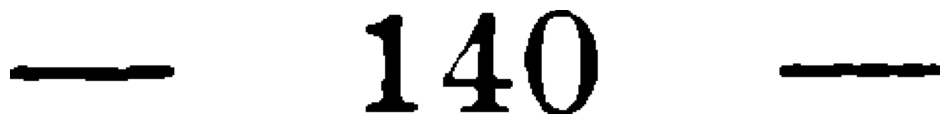

Ground truth: — 140 —
Tesseract: — 71419 —


In [28]:
from PIL import Image
import matplotlib.pyplot as plt

sample = df.iloc[0]

with Image.open(sample["colab_image_path"]) as img:
    line_image = img.convert("RGB")

plt.figure(figsize=(12, 2))
plt.imshow(line_image)
plt.axis("off")
plt.show()

print("Ground truth:", sample["ground_truth"])
print("Tesseract:", sample["ocr_text"])

In [30]:
low_conf_errors = df[
    (df["cer"] > 0) &
    (df["ocr_confidence"] < 80)
].sort_values("ocr_confidence").head(3)

high_conf_errors = df[
    (df["cer"] > 0) &
    (df["ocr_confidence"] >= 90)
].sort_values("ocr_confidence", ascending=False).head(4)

correct_lines = df[
    (df["cer"] == 0) &
    (df["ocr_confidence"] >= 90)
].sample(n=3, random_state=42)

pilot = pd.concat([
    low_conf_errors,
    high_conf_errors,
    correct_lines
]).copy()

pilot["sample_id"] = range(len(pilot))

print(
    pilot[[
        "sample_id",
        "page_id",
        "line_id",
        "ocr_text",
        "ground_truth",
        "ocr_confidence",
        "cer"
    ]].to_string(index=False)
)

 sample_id              page_id line_id                                                                       ocr_text                                                                  ground_truth  ocr_confidence      cer
         0 bebel_frau_1879_0146     l34                                                                   sammenfassen                                                                sammenfassen :        5.040161 0.142857
         1 bebel_frau_1879_0176      l9                                                                        — 1X) —                                                                       — 170 —       61.424169 0.285714
         2 bebel_frau_1879_0168     l59 andern Tace durch Conventbeschluss wieder einsetzt. Die \lIenschheit ıst seıt-  andern Tage durch Conventbeschluss wieder einsetzt. Die Menschheit ist seit-       67.926064 0.078947
         3 bebel_frau_1879_0176     l41       eulturen zu benutzen, zu welchem Zweck sie dann die Dächer flach b

In [ ]:
# The pilot reuses the same crop folder as the full experiment.
pilot["image_file"] = pilot["image_path"].map(lambda p: Path(p).name)
print("Pilot samples:", len(pilot))


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory (GB):",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1e9,
            2
        )
    )

CUDA available: True
GPU: Tesla T4
GPU memory (GB): 15.64


In [32]:
pilot_df = pilot.copy()
print(pilot_df[["sample_id", "page_id", "line_id", "ocr_text"]].to_string(index=False))


 sample_id line_id                                                                       ocr_text
         0     l34                                                                   sammenfassen
         1      l9                                                                        — 1X) —
         2     l59 andern Tace durch Conventbeschluss wieder einsetzt. Die \lIenschheit ıst seıt-
         3     l41       eulturen zu benutzen, zu welchem Zweck sie dann die Dächer flach bauten.
         4     l63  eine durch keine andere Einrichtung zu ersetzende ökonomische Basıs für einen
         5     l30           Gregor der Grosse: Es ıst noch nicht genug, das Gut Anderer nicht zu
         6     l19             Massregeln in Angriff genommen werden, so würde sich herausstellen
         7      l5                wie immer die dem Fortschritt der Menschheit feindlichen Mächte
         8     l63                                den Fluten der Nordsee versenkt werden können.“
         9     l12  

In [8]:
import torch

from transformers import (
    AutoProcessor,
    Qwen3VLForConditionalGeneration,
    BitsAndBytesConfig
)

MODEL_ID = "Qwen/Qwen3-VL-8B-Instruct"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

processor = AutoProcessor.from_pretrained(MODEL_ID)

model = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto",
    dtype=torch.float16,
    attn_implementation="sdpa"
)

model.eval()

print("Model loaded successfully")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

... (5 outputs left out)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/750 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

Model loaded successfully


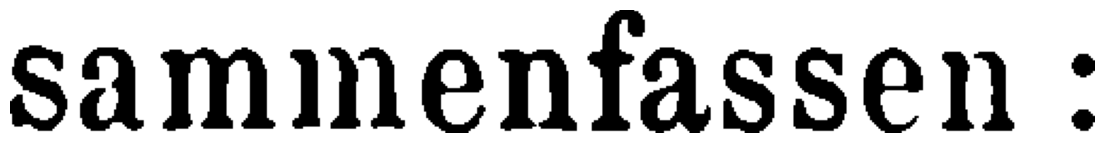

Tesseract OCR:
sammenfassen


In [33]:
from PIL import Image
import matplotlib.pyplot as plt

sample = pilot_df.iloc[0]

image_path = (
    IMAGE_DIR
    / sample["image_file"]
)

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(14, 3))
plt.imshow(image)
plt.axis("off")
plt.show()

print("Tesseract OCR:")
print(sample["ocr_text"])

In [34]:
PROMPT = """
You are an OCR correction assistant for historical
German printed documents.

You are given:
1. An image of a single historical text line.
2. A transcription produced by an OCR system.

Compare the transcription with the image and correct
only recognition errors supported by visual evidence.

Rules:
- Preserve the original historical German spelling.
- Preserve punctuation, capitalization, and hyphenation.
- Do not modernize or paraphrase the text.
- Do not invent missing or unreadable words.
- If the OCR transcription is correct, return it unchanged.
- Return only the final transcription, without explanations.

OCR transcription:
{ocr_text}
"""

In [35]:
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": image
            },
            {
                "type": "text",
                "text": PROMPT.format(
                    ocr_text=sample["ocr_text"]
                )
            }
        ]
    }
]

inputs = processor.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors="pt"
)

inputs.pop("token_type_ids", None)
inputs = inputs.to("cuda")

with torch.inference_mode():
    generated_ids = model.generate(
        **inputs,
        max_new_tokens=128,
        do_sample=False
    )

new_tokens = generated_ids[
    0, inputs["input_ids"].shape[-1]:
]

vlm_text = processor.decode(
    new_tokens,
    skip_special_tokens=True,
    clean_up_tokenization_spaces=False
).strip()

print("Tesseract OCR:")
print(sample["ocr_text"])

print("\nVLM correction:")
print(vlm_text)

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


Tesseract OCR:
sammenfassen

VLM correction:
sammenfassen:


In [ ]:
# jiwer is installed by requirements.txt.

In [37]:
from jiwer import cer, wer

ground_truth = sample["ground_truth"]
ocr_text = sample["ocr_text"]

print("GROUND TRUTH:")
print(ground_truth)

print("\nTESSERACT:")
print(ocr_text)

print("\nQWEN CORRECTION:")
print(vlm_text)

print("\nCharacter Error Rate:")
print(f"Tesseract: {cer(ground_truth, ocr_text):.2%}")
print(f"Qwen:      {cer(ground_truth, vlm_text):.2%}")

print("\nWord Error Rate:")
print(f"Tesseract: {wer(ground_truth, ocr_text):.2%}")
print(f"Qwen:      {wer(ground_truth, vlm_text):.2%}")

GROUND TRUTH:
sammenfassen :

TESSERACT:
sammenfassen

QWEN CORRECTION:
sammenfassen:

Character Error Rate:
Tesseract: 14.29%
Qwen:      7.14%

Word Error Rate:
Tesseract: 50.00%
Qwen:      100.00%


## Pilot Experiment — Ten Historical Text Lines

In [ ]:
import time
from tqdm import tqdm

pilot_results = []

for _, row in tqdm(pilot_df.iterrows(), total=len(pilot_df)):

    image_path = (
        IMAGE_DIR /
        row["image_file"]
    )

    with Image.open(image_path) as img:
        line_image = img.convert("RGB")

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": line_image},
            {
                "type": "text",
                "text": PROMPT.format(
                    ocr_text=row["ocr_text"]
                )
            }
        ]
    }]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt"
    )

    inputs.pop("token_type_ids", None)
    inputs = inputs.to("cuda")

    start_time = time.perf_counter()

    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=128,
            do_sample=False
        )

    elapsed = time.perf_counter() - start_time

    new_tokens = generated_ids[
        0, inputs["input_ids"].shape[-1]:
    ]

    corrected_text = processor.decode(
        new_tokens,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    ).strip()

    pilot_results.append({
        "sample_id": row["sample_id"],
        "page_id": row["page_id"],
        "line_id": row["line_id"],
        "ground_truth": row["ground_truth"],
        "ocr_text": row["ocr_text"],
        "vlm_text": corrected_text,
        "ocr_confidence": row["ocr_confidence"],
        "vlm_time_seconds": elapsed
    })

    pd.DataFrame(pilot_results).to_csv(
        PILOT_RESULTS_PATH,
        index=False
    )

print("Processed:", len(pilot_results))


  0%|          | 0/10 [00:00<?, ?it/s]

Processed: 10


In [39]:
results_df = pd.DataFrame(pilot_results)

results_df["ocr_cer"] = results_df.apply(
    lambda row: cer(row["ground_truth"], row["ocr_text"]),
    axis=1
)

results_df["vlm_cer"] = results_df.apply(
    lambda row: cer(row["ground_truth"], row["vlm_text"]),
    axis=1
)

results_df["cer_change"] = (
    results_df["vlm_cer"] - results_df["ocr_cer"]
)

print(results_df[[
    "line_id",
    "ocr_text",
    "vlm_text",
    "ocr_cer",
    "vlm_cer",
    "cer_change"
]].to_string(index=False))

print(
    "OCR corpus CER:",
    f"{cer(results_df['ground_truth'].tolist(), results_df['ocr_text'].tolist()):.2%}"
)

print(
    "VLM corpus CER:",
    f"{cer(results_df['ground_truth'].tolist(), results_df['vlm_text'].tolist()):.2%}"
)

'line_id                                                                       ocr_text                                                                      vlm_text  ocr_cer  vlm_cer  cer_change\n    l34                                                                   sammenfassen                                                                 sammenfassen: 0.142857 0.071429   -0.071429\n     l9                                                                        — 1X) —                                                                       — 170 — 0.285714 0.000000   -0.285714\n    l59 andern Tace durch Conventbeschluss wieder einsetzt. Die \\lIenschheit ıst seıt-  andern Tage durch Conventbeschluss wieder einsetzt. Die Menschheit ist seit- 0.078947 0.000000   -0.078947\n    l41       eulturen zu benutzen, zu welchem Zweck sie dann die Dächer flach bauten.      culturen zu benutzen, zu welchem Zweck sie dann die Dächer flach bauten. 0.013889 0.000000   -0.013889\n    l63  eine durc

OCR corpus CER: 2.81%
VLM corpus CER: 0.40%


In [40]:
print("Pilot results:", PILOT_RESULTS_PATH)
# Optional in Colab:
# from google.colab import files
# files.download(str(PILOT_RESULTS_PATH))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Full Dataset — VLM Correction

In [ ]:
import time
import torch
import pandas as pd

from pathlib import Path
from PIL import Image
from tqdm import tqdm

RESULTS_PATH = OUTPUT_DIR / "vlm_full_results.csv"

if RESULTS_PATH.exists():
    results = pd.read_csv(
        RESULTS_PATH,
        keep_default_na=False
    ).to_dict("records")
else:
    results = []

completed = {
    (str(r["page_id"]), str(r["line_id"]))
    for r in results
}

print("Previously processed:", len(completed))
print("Total samples:", len(df))

for _, row in tqdm(df.iterrows(), total=len(df)):

    key = (str(row["page_id"]), str(row["line_id"]))

    if key in completed:
        continue

    with Image.open(row["colab_image_path"]) as img:
        line_image = img.convert("RGB")

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": line_image},
            {
                "type": "text",
                "text": PROMPT.format(
                    ocr_text=row["ocr_text"]
                )
            }
        ]
    }]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt"
    )

    inputs.pop("token_type_ids", None)
    inputs = inputs.to("cuda")

    start_time = time.perf_counter()

    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=128,
            do_sample=False
        )

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start_time

    new_tokens = generated_ids[
        0, inputs["input_ids"].shape[-1]:
    ]

    corrected_text = processor.decode(
        new_tokens,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    ).strip()

    results.append({
        "page_id": row["page_id"],
        "line_id": row["line_id"],
        "ground_truth": row["ground_truth"],
        "ocr_text": row["ocr_text"],
        "vlm_text": corrected_text,
        "ocr_confidence": row["ocr_confidence"],
        "vlm_time_seconds": elapsed
    })

    completed.add(key)

    pd.DataFrame(results).to_csv(
        RESULTS_PATH,
        index=False,
        encoding="utf-8"
    )

print("Completed predictions:", len(results))

Previously processed: 0
Total samples: 164


  0%|          | 0/164 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


Completed predictions: 164


In [42]:
from jiwer import cer, wer

full_df = pd.read_csv(
    RESULTS_PATH,
    keep_default_na=False
)

assert len(full_df) == 164, "Some lines are missing."

ocr_cer = cer(
    full_df["ground_truth"].tolist(),
    full_df["ocr_text"].tolist()
)

vlm_cer = cer(
    full_df["ground_truth"].tolist(),
    full_df["vlm_text"].tolist()
)

ocr_wer = wer(
    full_df["ground_truth"].tolist(),
    full_df["ocr_text"].tolist()
)

vlm_wer = wer(
    full_df["ground_truth"].tolist(),
    full_df["vlm_text"].tolist()
)

print("=== Full Dataset Evaluation ===")

print(f"Tesseract CER: {ocr_cer:.2%}")
print(f"VLM CER:       {vlm_cer:.2%}")

print(f"Tesseract WER: {ocr_wer:.2%}")
print(f"VLM WER:       {vlm_wer:.2%}")

print(
    "Relative CER reduction:",
    f"{(ocr_cer - vlm_cer) / ocr_cer:.2%}"
)

=== Full Dataset Evaluation ===
Tesseract CER: 1.34%
VLM CER:       0.30%
Tesseract WER: 8.25%
VLM WER:       2.40%
Relative CER reduction: 77.54%


In [43]:
full_df["ocr_cer"] = full_df.apply(
    lambda r: cer(r["ground_truth"], r["ocr_text"]),
    axis=1
)

full_df["vlm_cer"] = full_df.apply(
    lambda r: cer(r["ground_truth"], r["vlm_text"]),
    axis=1
)

improved = (full_df["vlm_cer"] < full_df["ocr_cer"]).sum()
unchanged = (full_df["vlm_cer"] == full_df["ocr_cer"]).sum()
worsened = (full_df["vlm_cer"] > full_df["ocr_cer"]).sum()

print("Improved lines:", improved)
print("Unchanged CER:", unchanged)
print("Worsened lines:", worsened)

print("\nWorst VLM regressions:")

print(
    full_df.assign(
        cer_change=full_df["vlm_cer"] - full_df["ocr_cer"]
    ).sort_values(
        "cer_change",
        ascending=False
    )[
        ["page_id", "line_id",
         "ground_truth", "ocr_text",
         "vlm_text", "cer_change"]
    ].head(10).to_string(index=False)
)

Improved lines: 77
Unchanged CER: 79
Worsened lines: 8

Worst VLM regressions:
             page_id line_id                                                                   ground_truth                                                                       ocr_text                                                                       vlm_text  cer_change
bebel_frau_1879_0176     l61             ein Dreissigstel des gesammten Jagdreviers von Schottland beträgt.             ein Dreissigstel des gesammten Jagdreviers von Schottland beträgt.              ein Dreißigstel des gesammten Jagdreviers von Schottland beträgt.    0.030303
bebel_frau_1879_0168      l5          erklären und auf ihre eigenen Füsse stellen. Dies bedeutete: absolute          erklären und auf ihre eigenen Füsse stellen. Dies bedeutete: absolute           erklären und auf ihre eigenen Füße stellen. Dies bedeutete: absolute    0.028986
bebel_frau_1879_0146     l37                     mungsrecht. Einen Klassengegensatz gie